# DRUMMOTION — Entrenamiento, evaluación y exportación para web

Este notebook entrena el clasificador LSTM de cinco clases y prepara los archivos para integrarlo en una web estática.

**Clases:** `Crash`, `Ride`, `Tom`, `Hit_Tom`, `Neutral`.

## Antes de empezar
1. En Google Drive crea `DRUMMOTION_DATA/videos_convertidos/`.
2. Dentro crea una carpeta por clase, con videos MP4:
   - `Crash/`
   - `Ride/`
   - `Tom/`
   - `Hit_Tom/`
   - `Neutral/`
3. Incluye, idealmente, varias grabaciones independientes por clase (recomendado: al menos 5 por clase).
4. Abre este notebook en Google Colab y ejecuta las celdas en orden.

**No convierte MOV a MP4.** Haz esa conversión manualmente antes de subir los MP4.

## 1. Instalar dependencias

In [1]:
!pip -q install mediapipe opencv-python-headless scikit-learn seaborn

## 2. Conectar Drive y definir rutas

In [2]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import os, json, random, shutil, subprocess, sys, urllib.request, warnings
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.utils.class_weight import compute_class_weight

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

ROOT = Path('/content/drive/MyDrive/DRUMMOTION_DATA')
VIDEO_ROOT = ROOT / 'videos_convertidos'
CLIP_ROOT = ROOT / 'clips'
FEATURE_ROOT = ROOT / 'features'
OUT_ROOT = ROOT / 'exportacion_web'
POSE_TASK = Path('/content/pose_landmarker_full.task')
for p in [VIDEO_ROOT, CLIP_ROOT, FEATURE_ROOT, OUT_ROOT]:
    p.mkdir(parents=True, exist_ok=True)

CLASSES = ['Crash', 'Ride', 'Tom', 'Hit_Tom', 'Neutral']
SEQ_LEN = 30
CLIP_SECONDS = 2.0
LABEL_TO_ID = {name: i for i, name in enumerate(CLASSES)}
print('TensorFlow:', tf.__version__)
print('Ruta de videos:', VIDEO_ROOT)

Mounted at /content/drive
TensorFlow: 2.21.0
Ruta de videos: /content/drive/MyDrive/DRUMMOTION_DATA/videos_convertidos


## 3. Revisar videos MP4

In [3]:
video_paths = {}
for cls in CLASSES:
    folder = VIDEO_ROOT / cls
    files = sorted(folder.glob('*.mp4')) if folder.exists() else []
    video_paths[cls] = files
    print(f'{cls:10s}: {len(files)} video(s)')
    for f in files: print('   ', f.name)

missing = [c for c, fs in video_paths.items() if not fs]
if missing:
    raise FileNotFoundError('Faltan MP4 para: ' + ', '.join(missing) +
        '. Organiza los videos en videos_convertidos/<clase>/*.mp4')
if any(len(fs) < 3 for fs in video_paths.values()):
    print('ADVERTENCIA: para evaluar generalización, graba al menos 3 videos independientes por clase; idealmente 5 o más.')

Crash     : 2 video(s)
    P01_Crash_converted.mp4
    P02_Crash_converted.mp4
Ride      : 2 video(s)
    P01_Ride_converted.mp4
    P02_Ride_converted.mp4
Tom       : 2 video(s)
    P01_Tom_converted.mp4
    P02_Tom_converted.mp4
Hit_Tom   : 2 video(s)
    P01_Hit_Tom_converted.mp4
    P02_Hit_Tom_converted.mp4
Neutral   : 1 video(s)
    P01_Neutral_converted.mp4
ADVERTENCIA: para evaluar generalización, graba al menos 3 videos independientes por clase; idealmente 5 o más.


## 4. Crear clips sin convertir los videos

In [4]:
if CLIP_ROOT.exists(): shutil.rmtree(CLIP_ROOT)
CLIP_ROOT.mkdir(parents=True, exist_ok=True)
rows = []
for cls, files in video_paths.items():
    for video in files:
        cap = cv2.VideoCapture(str(video))
        fps = cap.get(cv2.CAP_PROP_FPS)
        total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        if not fps or fps <= 0 or total <= 0:
            cap.release(); print('Video ilegible, omitido:', video); continue
        frames_per_clip = max(1, int(round(CLIP_SECONDS * fps)))
        outdir = CLIP_ROOT / cls / video.stem
        outdir.mkdir(parents=True, exist_ok=True)
        clip_n = 0
        for start in range(0, total - frames_per_clip + 1, frames_per_clip):
            cap.set(cv2.CAP_PROP_POS_FRAMES, start)
            buf = []
            for _ in range(frames_per_clip):
                ok, fr = cap.read()
                if not ok: break
                buf.append(fr)
            if len(buf) != frames_per_clip: continue
            path = outdir / f'{video.stem}_{clip_n:04d}.mp4'
            h, w = buf[0].shape[:2]
            writer = cv2.VideoWriter(str(path), cv2.VideoWriter_fourcc(*'mp4v'), fps, (w,h))
            for fr in buf: writer.write(fr)
            writer.release()
            rows.append({'clip': str(path), 'label': cls, 'source': str(video)})
            clip_n += 1
        cap.release()
clips_df = pd.DataFrame(rows)
if clips_df.empty: raise RuntimeError('No se generaron clips. Verifica los MP4 y su duración.')
display(clips_df.groupby('label').size().reindex(CLASSES).to_frame('clips'))

,clips
label,
Crash,106
Ride,106
Tom,94
Hit_Tom,88
Neutral,103


## 5. Descargar y configurar MediaPipe Pose Landmarker

In [5]:
POSE_URL = 'https://storage.googleapis.com/mediapipe-models/pose_landmarker/pose_landmarker_full/float16/1/pose_landmarker_full.task'
if not POSE_TASK.exists(): urllib.request.urlretrieve(POSE_URL, POSE_TASK)

import mediapipe as mp
from mediapipe.tasks import python as mp_python
from mediapipe.tasks.python import vision
base_options = mp_python.BaseOptions(model_asset_path=str(POSE_TASK))
pose_options = vision.PoseLandmarkerOptions(
    base_options=base_options,
    running_mode=vision.RunningMode.VIDEO,
    num_poses=1,
    min_pose_detection_confidence=0.5,
    min_pose_presence_confidence=0.5,
    min_tracking_confidence=0.5
)
print('MediaPipe model bytes:', POSE_TASK.stat().st_size)

MediaPipe model bytes: 9398198


## 6. Extraer características (30 frames × 33 puntos × 4 valores)

In [6]:
def normalize_pose(landmarks):
    a = np.array([[p.x, p.y, p.z, p.visibility] for p in landmarks], dtype=np.float32)
    center = (a[23, :3] + a[24, :3]) / 2.0
    scale = np.linalg.norm(a[11, :2] - a[12, :2])
    if not np.isfinite(scale) or scale < 1e-4: scale = 1.0
    a[:, :3] = (a[:, :3] - center) / scale
    return a

def extract_sequence(path):
    cap = cv2.VideoCapture(str(path))
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    fps = cap.get(cv2.CAP_PROP_FPS)
    if total < 1:
        cap.release(); return None
    idxs = np.linspace(0, total-1, SEQ_LEN).astype(int)
    seq, prev_ms = [], -1
    with vision.PoseLandmarker.create_from_options(pose_options) as detector:
        for idx in idxs:
            cap.set(cv2.CAP_PROP_POS_FRAMES, int(idx))
            ok, frame = cap.read()
            if not ok:
                cap.release(); return None
            rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            image = mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb)
            ts = int(idx / fps * 1000) if fps and fps > 0 else idx * 33
            ts = max(ts, prev_ms + 1); prev_ms = ts
            result = detector.detect_for_video(image, ts)
            if result.pose_landmarks:
                seq.append(normalize_pose(result.pose_landmarks[0]))
            else:
                seq.append(np.zeros((33,4), dtype=np.float32))
    cap.release()
    seq = np.asarray(seq, dtype=np.float32)
    if seq.shape != (SEQ_LEN,33,4): return None
    if np.mean(seq[:,:,3] > 0.3) < 0.25: return None
    return seq.reshape(SEQ_LEN,132)

X_list, y_list, groups, used = [], [], [], []
for row in clips_df.itertuples(index=False):
    x = extract_sequence(row.clip)
    if x is not None:
        X_list.append(x); y_list.append(LABEL_TO_ID[row.label]); groups.append(row.source); used.append(row.clip)
X = np.asarray(X_list, dtype=np.float32)
y = np.asarray(y_list, dtype=np.int64)
groups = np.asarray(groups)
print('X shape:', X.shape, 'y shape:', y.shape)
if len(X) < 20: print('ADVERTENCIA: pocos ejemplos. Graba más videos por clase para mejorar la robustez.')
display(pd.Series([CLASSES[i] for i in y]).value_counts().reindex(CLASSES, fill_value=0).to_frame('secuencias'))

X shape: (497, 30, 132) y shape: (497,)


,secuencias
Crash,106
Ride,106
Tom,94
Hit_Tom,88
Neutral,103


## 7. Separar datos por video de origen

La separación por video es preferible porque los clips de una misma grabación son parecidos. Si no hay suficientes videos por clase para separar los grupos, el notebook detiene el entrenamiento y pide más grabaciones; esto evita reportar métricas engañosas.

In [9]:

# División estratificada por clips para poder continuar con el entrenamiento.
# IMPORTANTE: evaluación provisional; clips del mismo video pueden quedar
# en conjuntos diferentes y las métricas pueden ser optimistas.

import numpy as np
from sklearn.model_selection import train_test_split

# Comprobar cuántas secuencias válidas hay por clase
counts = {
    cls: int(np.sum(y == LABEL_TO_ID[cls]))
    for cls in CLASSES
}
print("Secuencias válidas por clase:", counts)

if any(n < 3 for n in counts.values()):
    raise RuntimeError(
        "Alguna clase tiene menos de 3 secuencias válidas. "
        "Revisa la extracción de poses."
    )

# Dividir las secuencias: 60% entrenamiento, 20% validación, 20% prueba
indices = np.arange(len(y))

train_idx, temp_idx = train_test_split(
    indices,
    test_size=0.40,
    random_state=SEED,
    stratify=y
)

val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    random_state=SEED,
    stratify=y[temp_idx]
)

X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val = X[val_idx], y[val_idx]
X_test, y_test = X[test_idx], y[test_idx]

print("Train/val/test:", len(train_idx), len(val_idx), len(test_idx))
print("Clases en entrenamiento:", np.unique(y_train))
print("Clases en validación:", np.unique(y_val))
print("Clases en prueba:", np.unique(y_test))
print("División provisional completada.")


Secuencias válidas por clase: {'Crash': 106, 'Ride': 106, 'Tom': 94, 'Hit_Tom': 88, 'Neutral': 103}
Train/val/test: 298 99 100
Clases en entrenamiento: [0 1 2 3 4]
Clases en validación: [0 1 2 3 4]
Clases en prueba: [0 1 2 3 4]
División provisional completada.


## 8. Entrenar el clasificador LSTM

In [10]:
weights = compute_class_weight(class_weight='balanced', classes=np.unique(y_train), y=y_train)
class_weights = {int(k): float(v) for k,v in zip(np.unique(y_train), weights)}

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(SEQ_LEN,132), name='pose_sequence'),
    tf.keras.layers.LSTM(64, return_sequences=True),
    tf.keras.layers.Dropout(0.30),
    tf.keras.layers.LSTM(32),
    tf.keras.layers.Dropout(0.30),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dropout(0.20),
    tf.keras.layers.Dense(len(CLASSES), activation='softmax', name='gesture_probabilities')
])
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.summary()
callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=12, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-5)
]
history = model.fit(X_train, y_train, validation_data=(X_val,y_val),
                    epochs=100, batch_size=16, class_weight=class_weights,
                    callbacks=callbacks, verbose=1)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 30, 64)         │        50,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 30, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gesture_probabilities (Dense)   │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 64,069 (250.27 KB)

 Trainable params: 64,069 (250.27 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 4s 38ms/step - accuracy: 0.2517 - loss: 1.5697 - val_accuracy: 0.5455 - val_loss: 1.3554 - learning_rate: 0.0010
Epoch 2/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.5671 - loss: 1.2379 - val_accuracy: 0.8586 - val_loss: 0.9317 - learning_rate: 0.0010
Epoch 3/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.6980 - loss: 0.9082 - val_accuracy: 0.8990 - val_loss: 0.6107 - learning_rate: 0.0010
Epoch 4/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.6711 - loss: 0.8825 - val_accuracy: 0.7475 - val_loss: 0.5928 - learning_rate: 0.0010
Epoch 5/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.7013 - loss: 0.7325 - val_accuracy: 0.7778 - val_loss: 0.4709 - learning_rate: 0.0010
Epoch 6/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.8087 - loss: 0.5288 - val_accuracy: 0.8990 - val_loss: 0.3019 - learning_rate: 0.0010
Epoch 7/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.8221 - loss: 0.3943 - 

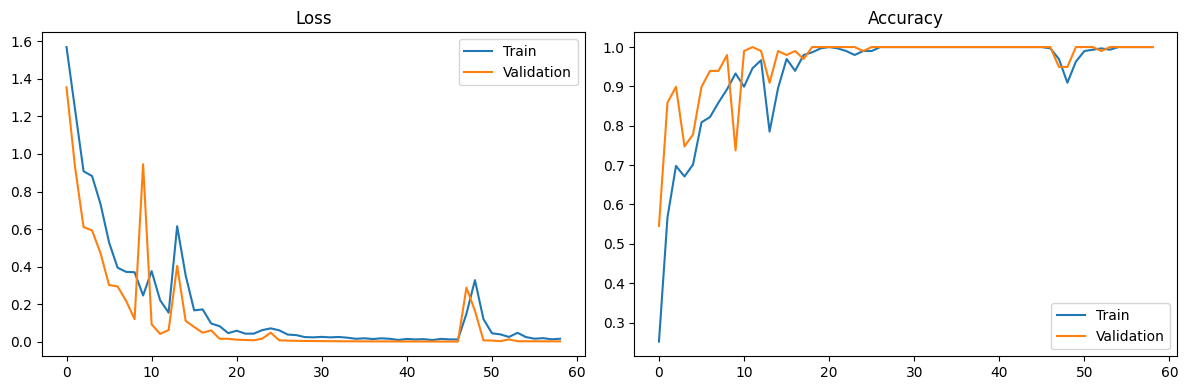

In [11]:
fig, ax = plt.subplots(1,2,figsize=(12,4))
ax[0].plot(history.history['loss'], label='Train'); ax[0].plot(history.history['val_loss'], label='Validation')
ax[0].set_title('Loss'); ax[0].legend()
ax[1].plot(history.history['accuracy'], label='Train'); ax[1].plot(history.history['val_accuracy'], label='Validation')
ax[1].set_title('Accuracy'); ax[1].legend()
plt.tight_layout(); plt.show()

## 9. Evaluar el conjunto de prueba

Test accuracy: 1.0
              precision    recall  f1-score   support

       Crash       1.00      1.00      1.00        22
        Ride       1.00      1.00      1.00        21
         Tom       1.00      1.00      1.00        19
     Hit_Tom       1.00      1.00      1.00        17
     Neutral       1.00      1.00      1.00        21

    accuracy                           1.00       100
   macro avg       1.00      1.00      1.00       100
weighted avg       1.00      1.00      1.00       100



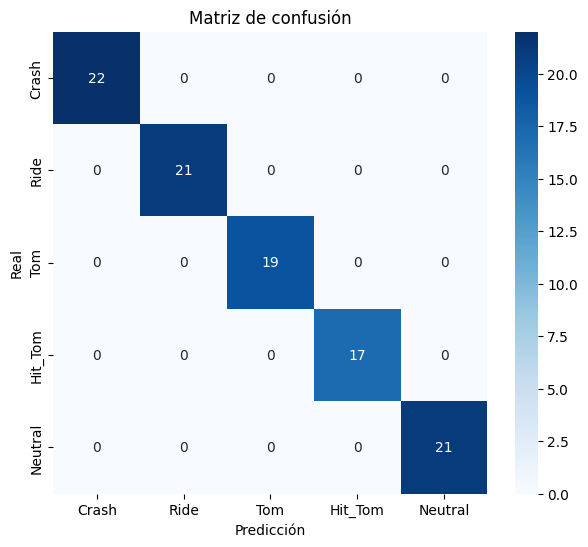

In [12]:
probs = model.predict(X_test, verbose=0)
pred = probs.argmax(axis=1)
acc = float(accuracy_score(y_test, pred))
print('Test accuracy:', round(acc,4))
print(classification_report(y_test, pred, labels=list(range(len(CLASSES))),
                            target_names=CLASSES, zero_division=0))
cm = confusion_matrix(y_test, pred, labels=list(range(len(CLASSES))))
plt.figure(figsize=(7,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASSES, yticklabels=CLASSES)
plt.xlabel('Predicción'); plt.ylabel('Real'); plt.title('Matriz de confusión')
plt.show()

## 10. Guardar modelo, etiquetas y resultados

In [34]:
OUT_ROOT.mkdir(parents=True, exist_ok=True)
model_path = OUT_ROOT / 'drummotion_lstm.keras'
model.save(model_path)
with open(OUT_ROOT/'labels.json','w',encoding='utf-8') as f:
    json.dump({str(i): c for i,c in enumerate(CLASSES)}, f, ensure_ascii=False, indent=2)
metadata = {
    'project':'DRUMMOTION', 'classes':CLASSES, 'sequence_length':SEQ_LEN,
    'input_shape':[SEQ_LEN,132], 'landmarks':33,
    'features_per_landmark':['x','y','z','visibility'],
    'normalization':'hip center; scale by shoulder width',
    'fps_sampling':'30 equally spaced frames per 2-second clip',
    'class_to_id':LABEL_TO_ID, 'test_accuracy':acc,
    'source_videos_per_class':sources_per_class,
    'split':'by original source video',
    'important':'Web inference must use the exact same normalization and sequence shape.'
}
with open(OUT_ROOT/'metadata.json','w',encoding='utf-8') as f: json.dump(metadata,f,ensure_ascii=False,indent=2)
report = classification_report(y_test,pred,labels=list(range(len(CLASSES))),target_names=CLASSES,
                                output_dict=True,zero_division=0)
with open(OUT_ROOT/'metrics.json','w',encoding='utf-8') as f:
    json.dump({'accuracy':acc,'report':report,'confusion_matrix':cm.tolist()},f,ensure_ascii=False,indent=2)
with open(OUT_ROOT/'history.json','w',encoding='utf-8') as f:
    json.dump(history.history,f,ensure_ascii=False,indent=2)
print('Modelo guardado en:', model_path)
print('Archivos de salida:', [p.name for p in OUT_ROOT.iterdir()])

Modelo guardado en: /content/drive/MyDrive/DRUMMOTION_DATA/exportacion_web/drummotion_lstm.keras
Archivos de salida: ['drummotion_lstm.keras', 'labels.json', 'metadata.json', 'metrics.json', 'history.json', 'tfjs_model']


## 11. Exportar LSTM a TensorFlow.js

> Add blockquote



Esta celda intenta instalar el conversor en un entorno virtual separado para no reemplazar TensorFlow del entrenamiento. Si la instalación falla por incompatibilidades de versiones, el modelo `.keras` y los archivos de metadatos quedan guardados; usa la guía README para convertirlo en un entorno limpio de Python.

El resultado esperado es una carpeta `exportacion_web/tfjs_model/` que contenga `model.json` y uno o más archivos de pesos.

In [43]:

import subprocess
import shutil
from pathlib import Path

venv_dir = Path("/content/drummotion_tfjs_env")
py = venv_dir / "bin" / "python"
uv = shutil.which("uv")

assert py.exists(), f"No existe el Python del entorno: {py}"
assert uv, "No se encuentra uv en Colab."

# Reparar pip dentro del entorno aislado
r = subprocess.run(
    [uv, "pip", "install", "--python", str(py),
     "pip", "setuptools==81.0.0"],
    capture_output=True,
    text=True
)

print(r.stdout[-3000:])
print(r.stderr[-5000:])

if r.returncode != 0:
    raise RuntimeError("No se pudo reparar pip en el entorno.")

# Comprobar las dependencias
r = subprocess.run(
    [
        str(py), "-c",
        "import pip; print('pip:', pip.__version__); "
        "import pkg_resources; print('pkg_resources: OK'); "
        "import tensorflowjs; print('TensorFlow.js: OK')"
    ],
    capture_output=True,
    text=True
)

print(r.stdout)
print(r.stderr[-5000:])

if r.returncode != 0:
    raise RuntimeError(
        "El entorno todavía tiene un error. Revisa el mensaje anterior."
    )

print("Entorno reparado. Ya puedes volver a intentar la conversión.")



Using Python 3.11.18 environment at: drummotion_tfjs_env
Resolved 2 packages in 153ms
Prepared 2 packages in 227ms
Uninstalled 1 package in 11ms
Installed 2 packages in 32ms
 + pip==26.3
 - setuptools==84.2.1
 + setuptools==81.0.0

pip: 26.3
pkg_resources: OK
TensorFlow.js: OK

<string>:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
2026-11-25 12:19:06.247724: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-11-25 12:19:06.249978: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-11-25 12:19:06.251545: E external/local_

In [45]:

import shutil
import subprocess
from pathlib import Path
import tensorflow as tf

OUT_ROOT = Path(
    "/content/drive/MyDrive/DRUMMOTION_DATA/exportacion_web"
)
keras_path = OUT_ROOT / "drummotion_lstm.keras"
saved_model_dir = Path("/content/drummotion_saved_model")
tfjs_dir = OUT_ROOT / "tfjs_model"
py = Path("/content/drummotion_tfjs_env/bin/python")

assert keras_path.exists(), f"No existe el modelo: {keras_path}"
assert py.exists(), f"No existe el conversor: {py}"

# 1. Abrir el modelo con el TensorFlow actual de Colab
model = tf.keras.models.load_model(
    keras_path, compile=False
)
print("Modelo cargado:", model.input_shape, "->", model.output_shape)

# 2. Exportar a SavedModel con Keras 3
if saved_model_dir.exists():
    shutil.rmtree(saved_model_dir)

model.export(str(saved_model_dir))
print("SavedModel exportado:", saved_model_dir)

# 3. Convertir SavedModel a TensorFlow.js GraphModel
if tfjs_dir.exists():
    shutil.rmtree(tfjs_dir)
tfjs_dir.mkdir(parents=True, exist_ok=True)

result = subprocess.run(
    [
        str(py), "-m",
        "tensorflowjs.converters.converter",
        "--input_format=tf_saved_model",
        "--signature_name=serving_default",
        "--saved_model_tags=serve",
        str(saved_model_dir),
        str(tfjs_dir)
    ],
    capture_output=True,
    text=True
)

print("\nCódigo de salida:", result.returncode)
print("\nSALIDA:\n", result.stdout[-4000:])
print("\nERROR:\n", result.stderr[-8000:])

model_json = tfjs_dir / "model.json"

if result.returncode != 0 or not model_json.exists():
    raise RuntimeError(
        "La conversión a SavedModel también falló. "
        "Revisa el bloque ERROR anterior."
    )

print("\nSe generó model.json.")
print("Archivos:", [p.name for p in tfjs_dir.iterdir()])
print("Nota: esta conversión produce un GraphModel.")


Modelo cargado: (None, 30, 132) -> (None, 5)
Saved artifact at '/content/drummotion_saved_model'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 30, 132), dtype=tf.float32, name='pose_sequence')
Output Type:
  TensorSpec(shape=(None, 5), dtype=tf.float32, name=None)
Captures:
  135698419774288: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135698419771408: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135698419772368: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135698444496784: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135698419767184: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135698419775632: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135698419775440: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135698419771600: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135698418895760: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135698418895568: TensorSpec

## 12. Preparar paquete web exportado

Copia los archivos del modelo TFJS y las etiquetas a una carpeta de despliegue. El frontend incluido en el ZIP usa MediaPipe en el navegador y TensorFlow.js para el clasificador. Revisa `README_DRUMMOTION.md` antes de publicar y prueba primero en HTTPS o localhost.

In [46]:

from pathlib import Path
import importlib.util

print("Modelo Keras:", Path(model_path).exists())
print("Conversor TFJS disponible:",
      importlib.util.find_spec("tensorflowjs") is not None)
print("Carpeta TFJS:", OUT_ROOT / "tfjs_model")
print("Existe model.json:",
      (OUT_ROOT / "tfjs_model" / "model.json").exists())
print("SavedModel:", Path("/content/drummotion_saved_model/saved_model.pb").exists())


Modelo Keras: True
Conversor TFJS disponible: True
Carpeta TFJS: /content/drive/MyDrive/DRUMMOTION_DATA/exportacion_web/tfjs_model
Existe model.json: True
SavedModel: True


In [47]:
DEPLOY_ROOT = ROOT / 'paquete_web'
DEPLOY_ROOT.mkdir(parents=True, exist_ok=True)
if (OUT_ROOT/'tfjs_model'/'model.json').exists():
    target = DEPLOY_ROOT/'models'/'gesture_model'
    if target.exists(): shutil.rmtree(target)
    target.mkdir(parents=True, exist_ok=True)
    for src in (OUT_ROOT/'tfjs_model').iterdir():
        if src.is_file(): shutil.copy2(src, target/src.name)
    shutil.copy2(OUT_ROOT/'labels.json', DEPLOY_ROOT/'labels.json')
    shutil.copy2(OUT_ROOT/'metadata.json', DEPLOY_ROOT/'metadata.json')
    print('Modelo web copiado a:', target)
else:
    print('No hay modelo TFJS todavía. Revisa la celda de exportación.')

Modelo web copiado a: /content/drive/MyDrive/DRUMMOTION_DATA/paquete_web/models/gesture_model
